# Toxicity Classification in Multiplayer Game Chat: TF-IDF with Classical Machine Learning

**Mini Project | Machine Learning** |  **Team:** Amogh and Arvind Ajay Bharadwaj  |  **Part:** TF-IDF features, SVM, Naive Bayes, KNN and Random Forest

---

### Contents
1. Objective and scope
2. Setup and reproducibility
3. Data loading and inspection
4. Feature extraction (TF-IDF)
5. Model training and evaluation
6. Results
7. Confusion matrices
8. Error analysis
9. Interactive prediction
10. Discussion, limitations and conclusions

## 1. Objective and scope

**Task.** Classify an in-game chat message into one of three classes:

| Label | Class | Description |
|---|---|---|
| 0 | Neutral / positive | Ordinary game talk, praise, strategy |
| 1 | Negative attitude | Complaints, blame, mocking of skill |
| 2 | Derogatory | Slurs and personal abuse |

**Scope of this notebook.** TF-IDF feature extraction and the classical models:
three binary SVMs (neutral vs toxic), a dictionary-based Naive Bayes baseline, Naive Bayes on TF-IDF,
K-Nearest Neighbours (K = 1, 2, 3, 6) and three Random Forest configurations.
The neural models (Word2Vec / GloVe embeddings, feed-forward network, LSTM) are covered in the companion notebook by Arvind.

**Evaluation protocol.** All models are trained on the training split and evaluated once on the held-out test split.
Both team members use the same `train.csv` and `test.csv`, so results are directly comparable.
Reported metrics: accuracy, per-class precision, recall and F1, macro-F1 and confusion matrices.

## 2. Setup and reproducibility

In [1]:
import os
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support)
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

SEED = 42                      # fixed seed for reproducible results
LABELS = [0, 1, 2]
CLASS_NAMES = ["0 neutral/positive", "1 negative attitude", "2 derogatory"]

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)

**Input files.** `train.csv` and `test.csv` (columns `comment_text`, `label`) must be in the working directory.
In Google Colab the cell below prompts for an upload if they are missing.

In [2]:
if not (os.path.exists("train.csv") and os.path.exists("test.csv")):
    from google.colab import files
    files.upload()   # select train.csv and test.csv

## 3. Data loading and inspection

The dataset consists of hand-labelled chat messages from two public sources (Dota 2 and League of Legends chat logs),
following the data setup of the reference paper. Text is lower-cased and URLs are removed.

In [3]:
def load(path):
    df = pd.read_csv(path).rename(columns={"comment_text": "message"})
    df["message"] = (df["message"].astype(str).str.lower()
                     .str.replace(r"http\S+", "", regex=True).str.strip())
    return df

train, test = load("train.csv"), load("test.csv")
y_train, y_test = train["label"].values, test["label"].values

print(f"Training messages: {len(train):,} | Test messages: {len(test):,}")
print("\nClass distribution (train):")
print(train["label"].value_counts().sort_index().rename("messages").to_frame())
train.head(10)

Training messages: 21,120 | Test messages: 6,600

Class distribution (train):
       messages
label          
0          7040
1          7040
2          7040


,message,label
0,we had to tp at the same fucking palce,1
1,lol where is your shrine noob?,1
2,we cant win against this shit,1
3,u two are idiot,2
4,my team retard feed your team retard,2
5,can u stfu and check the ranks,1
6,dont be rude you cunt,2
7,fizz jungle gank more ofthen then u,0
8,talon of shit,1
9,these guys are stupid as shit,2


**Data integrity checks.** Duplicate messages that appear in both the training and test sets would inflate scores
(data leakage), particularly for instance-based models such as KNN.

In [4]:
n_dup_train = train["message"].duplicated().sum()
overlap = set(train["message"]) & set(test["message"])
print(f"Duplicate messages within train : {n_dup_train}")
print(f"Messages shared by train and test: {len(overlap)}")

Duplicate messages within train : 0
Messages shared by train and test: 0


## 4. Feature extraction (TF-IDF)

Classifiers require numeric input. **TF-IDF** (term frequency, inverse document frequency) represents each message as a
vector with one weight per vocabulary word: a word scores high when it is frequent in the message and rare across the corpus,
and low when it is common everywhere.

A minimal illustration:

In [5]:
demo_msgs = ["gg wp", "you are a noob", "noob noob team"]
demo = TfidfVectorizer()
grid = demo.fit_transform(demo_msgs)
pd.DataFrame(grid.toarray().round(2), columns=demo.get_feature_names_out(), index=demo_msgs)

,are,gg,noob,team,wp,you
gg wp,0.00,0.71,0.00,0.00,0.71,0.00
you are a noob,0.62,0.00,0.47,0.00,0.00,0.62
noob noob team,0.00,0.00,0.84,0.55,0.00,0.00


**Leakage prevention.** The vocabulary and IDF weights are learned from the training split only (`fit_transform`).
The test split is transformed with the learned vocabulary (`transform`) and never influences feature construction.

In [6]:
tfidf = TfidfVectorizer()
X_train = tfidf.fit_transform(train["message"])
X_test = tfidf.transform(test["message"])
print(f"Feature matrix: train {X_train.shape}, test {X_test.shape} "
      f"(vocabulary size {X_train.shape[1]:,})")

Feature matrix: train (21120, 7612), test (6600, 7612) (vocabulary size 7,612)


## 5. Model training and evaluation

| Model | Principle |
|---|---|
| SVM (linear, RBF, polynomial) | Finds the maximum-margin separating boundary; here applied to the **binary** task (class 0 vs classes 1 and 2 merged) |
| Naive Bayes | Applies Bayes' rule with a conditional-independence assumption over word features |
| K-Nearest Neighbours | Predicts the majority label among the K most similar training messages |
| Random Forest | Ensemble of decision trees trained on bootstrap samples; prediction by majority vote |

A helper function records accuracy, per-class precision, recall and F1, and macro-F1 for every model.

In [7]:
rows, preds = [], {}

def record(name, y_true, y_pred, labels):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    row = {"model": name,
           "accuracy": accuracy_score(y_true, y_pred),
           "macro_f1": f1_score(y_true, y_pred, average="macro", labels=labels, zero_division=0)}
    for i, lab in enumerate(labels):
        row[f"precision_c{lab}"], row[f"recall_c{lab}"], row[f"f1_c{lab}"] = p[i], r[i], f[i]
    rows.append(row)
    preds[name] = y_pred
    print(f"{name:40s} accuracy = {row['accuracy']:.4f}   macro-F1 = {row['macro_f1']:.4f}")

### 5.1 Binary SVMs (neutral vs toxic)

In [8]:
yb_train = np.where(y_train == 0, 1, -1)   # +1 = neutral, -1 = toxic (classes 1 and 2 merged)
yb_test = np.where(y_test == 0, 1, -1)

for name, kernel in [("SVM linear (binary)", "linear"),
                     ("SVM rbf (binary)", "rbf"),
                     ("SVM poly (binary)", "poly")]:
    model = SVC(kernel=kernel).fit(X_train, yb_train)
    record(name, yb_test, model.predict(X_test), [1, -1])

SVM linear (binary)                      accuracy = 0.9885   macro-F1 = 0.9871


SVM rbf (binary)                         accuracy = 0.9867   macro-F1 = 0.9851


SVM poly (binary)                        accuracy = 0.9564   macro-F1 = 0.9501


### 5.2 Baseline: Naive Bayes on a toxic-word dictionary

The baseline classifier only observes a fixed dictionary of toxic words and phrases.
The dictionary is derived from the **training split** (words that occur far more often in classes 1 and 2 than in class 0),
after removing common function words. The `remove` set can be edited to refine the dictionary manually.

In [9]:
tokenize = lambda text: re.findall(r"[a-z']+", text)
doc_freq_neutral = Counter(w for t in train[train.label == 0].message for w in set(tokenize(t)))
doc_freq_toxic = Counter(w for t in train[train.label > 0].message for w in set(tokenize(t)))

remove = {"you", "are", "this", "your", "like", "why", "what", "how", "was", "only", "who", "know",
          "because", "really", "have", "with", "that", "they", "just", "can", "get", "for", "the",
          "and", "not", "but", "all", "from", "its", "too", "when"}

candidates = [(w, n) for w, n in doc_freq_toxic.items()
              if n >= 15 and n >= 4 * (doc_freq_neutral.get(w, 0) + 1) and len(w) > 2 and w not in remove]
phrases = [w for w, _ in sorted(candidates, key=lambda x: -x[1])][:165]
print(f"Dictionary size: {len(phrases)} words. First 60: {phrases[:60]}")

Dictionary size: 165 words. First 60: ['report', 'team', 'fucking', 'fuck', 'stupid', 'retarded', 'retard', 'shit', 'idiot', 'bitch', 'noob', 'bad', 'feed', 'mother', 'retards', 'trash', 'suck', 'idiots', 'wtf', 'son', 'cunt', 'useless', 'russian', 'mom', 'dick', 'moron', 'fucked', 'think', 'hate', 'dog', 'player', 'faggot', 'easy', 'shut', 'whore', 'his', "you're", 'troll', 'people', 'off', 'cause', 'did', 'stfu', 'russians', 'even', 'cunts', "he's", 'fuckin', 'than', 'such', 'these', 'ass', 'bitches', 'worst', 'yourself', 'nigga', 'lose', 'nigger', 'cuz', 'feeding']


In [10]:
dict_vectorizer = CountVectorizer(vocabulary=phrases)
nb_baseline = MultinomialNB().fit(dict_vectorizer.transform(train["message"]), y_train)
record("Naive Bayes baseline (word list)", y_test,
       nb_baseline.predict(dict_vectorizer.transform(test["message"])), LABELS)

Naive Bayes baseline (word list)         accuracy = 0.9238   macro-F1 = 0.9234


### 5.3 Multiclass models on TF-IDF features (labels 0 / 1 / 2)
This cell takes approximately two minutes.

In [11]:
models = {
    "Naive Bayes (TF-IDF)": MultinomialNB(),
    "KNN K=1": KNeighborsClassifier(n_neighbors=1),
    "KNN K=2": KNeighborsClassifier(n_neighbors=2),
    "KNN K=3": KNeighborsClassifier(n_neighbors=3),
    "KNN K=6": KNeighborsClassifier(n_neighbors=6),
    "Random Forest (Gini)": RandomForestClassifier(criterion="gini", random_state=SEED, n_jobs=-1),
    "Random Forest (Entropy)": RandomForestClassifier(criterion="entropy", random_state=SEED, n_jobs=-1),
    "Random Forest (Entropy, max_depth=32)": RandomForestClassifier(
        criterion="entropy", max_depth=32, random_state=SEED, n_jobs=-1),
}

fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    record(name, y_test, model.predict(X_test), LABELS)

Naive Bayes (TF-IDF)                     accuracy = 0.9177   macro-F1 = 0.9174


KNN K=1                                  accuracy = 0.7380   macro-F1 = 0.7363


KNN K=2                                  accuracy = 0.7242   macro-F1 = 0.7209


KNN K=3                                  accuracy = 0.7606   macro-F1 = 0.7570


KNN K=6                                  accuracy = 0.7944   macro-F1 = 0.7917


Random Forest (Gini)                     accuracy = 0.9439   macro-F1 = 0.9435


Random Forest (Entropy)                  accuracy = 0.9424   macro-F1 = 0.9421


Random Forest (Entropy, max_depth=32)    accuracy = 0.9130   macro-F1 = 0.9120


## 6. Results

**Metric definitions.**
*Accuracy*: share of test messages classified correctly.
*Precision* (per class): of the messages predicted as that class, the share that truly belong to it.
*Recall* (per class): of the messages truly in that class, the share that were found.
*F1*: harmonic mean of precision and recall. *Macro-F1*: unweighted mean of the per-class F1 scores.

In [12]:
results = pd.DataFrame(rows).round(4)
results.to_csv("results_classical_ml.csv", index=False)

is_binary = results["model"].str.contains("binary")

print("Multiclass models")
display(results[~is_binary].set_index("model")[
    ["accuracy", "precision_c0", "recall_c0", "f1_c0",
     "precision_c1", "recall_c1", "f1_c1",
     "precision_c2", "recall_c2", "f1_c2", "macro_f1"]])

print("Binary SVMs (c1 = neutral, c-1 = toxic)")
display(results[is_binary].set_index("model")[
    ["accuracy", "precision_c1", "recall_c1", "f1_c1",
     "precision_c-1", "recall_c-1", "f1_c-1", "macro_f1"]])

Multiclass models


,accuracy,precision_c0,recall_c0,f1_c0,precision_c1,recall_c1,f1_c1,precision_c2,recall_c2,f1_c2,macro_f1
model,,,,,,,,,,,
Naive Bayes baseline (word list),0.9238,0.8664,0.9905,0.9243,0.9623,0.8477,0.9014,0.9562,0.9332,0.9446,0.9234
Naive Bayes (TF-IDF),0.9177,0.9626,0.9477,0.9551,0.9266,0.8436,0.8832,0.8704,0.9618,0.9138,0.9174
KNN K=1,0.7380,0.7366,0.7982,0.7661,0.7135,0.6350,0.6720,0.7609,0.7809,0.7707,0.7363
KNN K=2,0.7242,0.6562,0.9136,0.7638,0.7041,0.6036,0.6500,0.8734,0.6555,0.7489,0.7209
KNN K=3,0.7606,0.7144,0.8700,0.7846,0.7830,0.6118,0.6869,0.7993,0.8000,0.7996,0.7570
KNN K=6,0.7944,0.7580,0.8982,0.8221,0.8106,0.6673,0.7320,0.8245,0.8177,0.8211,0.7917
Random Forest (Gini),0.9439,0.9392,0.9836,0.9609,0.9524,0.8914,0.9209,0.9410,0.9568,0.9488,0.9435
Random Forest (Entropy),0.9424,0.9387,0.9809,0.9593,0.9461,0.8941,0.9194,0.9428,0.9523,0.9475,0.9421
"Random Forest (Entropy, max_depth=32)",0.9130,0.8938,0.9755,0.9328,0.9428,0.8236,0.8792,0.9082,0.9400,0.9238,0.9120


Binary SVMs (c1 = neutral, c-1 = toxic)


,accuracy,precision_c1,recall_c1,f1_c1,precision_c-1,recall_c-1,f1_c-1,macro_f1
model,,,,,,,,
SVM linear (binary),0.9885,0.9733,0.9927,0.9829,0.9963,0.9864,0.9913,0.9871
SVM rbf (binary),0.9867,0.9677,0.9932,0.9803,0.9965,0.9834,0.9899,0.9851
SVM poly (binary),0.9564,0.9650,0.9018,0.9323,0.9525,0.9836,0.9678,0.9501


In [13]:
multi = results[~is_binary].set_index("model")
best = multi["macro_f1"].idxmax()
print(f"Best multiclass model by macro-F1: {best} "
      f"(accuracy {multi.loc[best, 'accuracy']:.4f}, macro-F1 {multi.loc[best, 'macro_f1']:.4f})")
print(f"Weakest class on average (F1): class "
      f"{multi[['f1_c0', 'f1_c1', 'f1_c2']].mean().idxmin()[-1]}")
print("\nMean accuracy by model family:")
family = multi["accuracy"].groupby(lambda m: m.split(" (")[0].split(" K=")[0]).mean().round(4)
print(family.to_string())

Best multiclass model by macro-F1: Random Forest (Gini) (accuracy 0.9439, macro-F1 0.9435)
Weakest class on average (F1): class 1

Mean accuracy by model family:
model
KNN                     0.7543
Naive Bayes             0.9177
Naive Bayes baseline    0.9238
Random Forest           0.9331


## 7. Confusion matrices

Rows correspond to the true class and columns to the predicted class. Diagonal entries are correct predictions.
Each cell shows the count and the percentage of the true class.

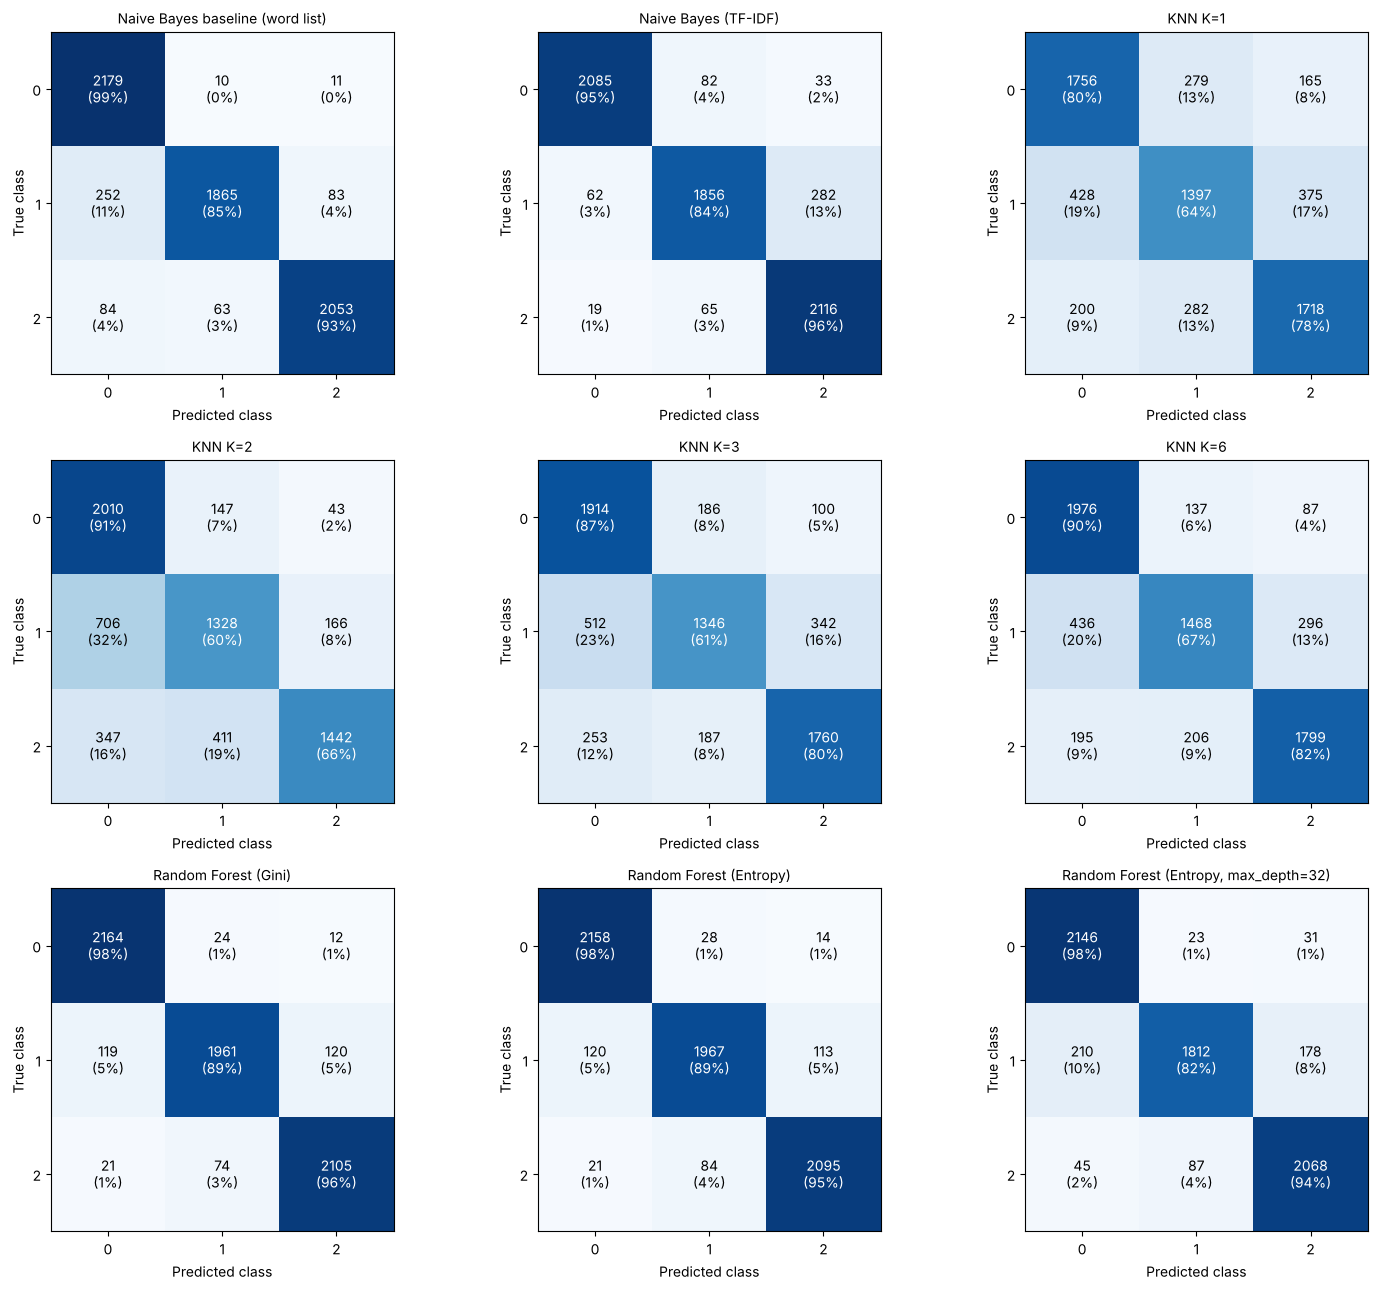

In [14]:
multi_names = [n for n in preds if "binary" not in n]
fig, axes = plt.subplots(3, 3, figsize=(15, 13))
for ax, name in zip(axes.ravel(), multi_names):
    cm = confusion_matrix(y_test, preds[name], labels=LABELS)
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n({pct[i, j]:.0%})", ha="center", va="center",
                    color="white" if pct[i, j] > 0.5 else "black")
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.savefig("confusion_matrices_classical_ml.png", dpi=150)
plt.show()

## 8. Error analysis

The best-performing multiclass model (Random Forest, Gini) is examined to identify systematic failure modes.
The table below shows which true classes are most often confused, followed by a random sample of misclassified messages.

In [15]:
rf = fitted["Random Forest (Gini)"]
errors = test.assign(predicted=preds["Random Forest (Gini)"])
errors = errors[errors["label"] != errors["predicted"]]

print(f"Misclassified: {len(errors)} of {len(test)} ({len(errors) / len(test):.1%})")
print("\nMost frequent confusions (true class -> predicted class):")
print(errors.groupby(["label", "predicted"]).size().sort_values(ascending=False)
      .rename("count").to_frame())

Misclassified: 370 of 6600 (5.6%)

Most frequent confusions (true class -> predicted class):
                 count
label predicted       
1     2            120
      0            119
2     1             74
0     1             24
2     0             21
0     2             12


In [16]:
errors.sample(20, random_state=SEED)[["message", "label", "predicted"]].reset_index(drop=True)

,message,label,predicted
0,gg ez go throne,1,0
1,managed to fucken hit nothing with def blast,1,0
2,that lee sin is so fucking good,0,1
3,i will blame mid,1,0
4,pick slardar is idiot,1,2
5,my team is shittttttt,1,2
6,you are useless russian dog stfu,2,1
7,i dont give a fuck about your thoughts,1,2
8,that set is fucking awesome,0,1
9,fuck u and your potato hero,1,2


**Observations (to be completed after reviewing the sample above).**
Typical causes of error in this task include: mild insults lying on the boundary between classes 1 and 2;
slang, abbreviations or deliberate misspellings absent from the training vocabulary; very short messages with little signal;
and labels that are inherently subjective.

## 9. Interactive prediction

The function below classifies any message with the Random Forest (Gini) model and reports the predicted class with its probability.

In [17]:
def predict_message(msg):
    probs = rf.predict_proba(tfidf.transform([msg.lower()]))[0]
    k = probs.argmax()
    print(f"{msg!r:45s} -> {CLASS_NAMES[k]}   (confidence {probs[k]:.0%})")

for message in ["gg well played", "push mid together", "you are so bad noob",
                "report this feeder", "shut up idiot", "thanks for the carry"]:
    predict_message(message)

'gg well played'                              -> 0 neutral/positive   (confidence 97%)
'push mid together'                           -> 0 neutral/positive   (confidence 97%)
'you are so bad noob'                         -> 1 negative attitude   (confidence 84%)
'report this feeder'                          -> 1 negative attitude   (confidence 96%)
'shut up idiot'                               -> 2 derogatory   (confidence 95%)
'thanks for the carry'                        -> 0 neutral/positive   (confidence 98%)


In [18]:
predict_message("type your message here")

'type your message here'                      -> 2 derogatory   (confidence 55%)


## 10. Discussion, limitations and conclusions

**Findings**
- Tree ensembles and linear models on TF-IDF features perform strongly on this dataset. The linear SVM is the strongest binary classifier and Random Forest is the strongest three-class classifier.
- Restricting Random Forest depth (`max_depth=32`) lowers performance relative to unrestricted trees, indicating that deeper trees capture useful word interactions.
- KNN is clearly weaker than the other families. Its accuracy increases with K, which is consistent with high-dimensional sparse text vectors where single nearest neighbours are noisy.
- Class 1 (negative attitude) is the hardest class for nearly all models, because it sits between neutral talk and outright abuse.

**Comparison with the reference paper.** The paper reports very high KNN accuracy for K = 1. In our split no message occurs in both train and test (Section 3),
so KNN cannot benefit from duplicate or near-duplicate messages. The much lower KNN scores here suggest that the paper's figure was inflated by such overlap.
Our classes are also exactly balanced (one third each), whereas the paper's were imbalanced.

**Limitations**
- The bag-of-words representation ignores word order and context, so sarcasm and negation are difficult.
- The model only recognises words seen in training; new slang and intentional misspellings are ignored.
- Labels were assigned manually and the boundary between classes 1 and 2 is subjective.
- The dictionary baseline was derived from the training data, which makes it stronger than a purely hand-written list.
- Results are from a single train/test split; no confidence intervals or cross-validation were computed.

**Possible extensions.** Character n-gram features (robust to misspellings), cross-validation, and comparison with the neural models in the companion notebook.